# Session 1 — Reading a Dataset

In Session 0 the dataset arrived ready to use. Real data rarely does: it has gaps, repeated rows and values that can't be true, and a model trained on it will learn from all of that without complaint. This session is about finding those problems before any model is built.

We use a made-up table of 500 students on an introductory course, with a column saying whether each one passed. The table has four problems planted in it. The same table (generated by the same function, with the same seed) is used again in Session 2, where we fix what we find here.

**By the end of the session you should be able to:**

1. run a short checklist (types, missing values, duplicates, impossible values) on any new table;
2. read a target column and a few plots well enough to know what a model will find easy or hard;
3. write each finding down as a decision about what to do next.

**To run it yourself** you need `numpy`, `pandas` and `matplotlib`. The outputs are already saved in the notebook. It runs in a few seconds, and the numbers should match exactly because the data is generated from a fixed seed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def make_students(seed=42, n=500):
    """Synthetic course data shared by Sessions 1 and 2: same seed, same rows, same planted problems."""
    rng = np.random.default_rng(seed)
    study_hours = np.clip(rng.normal(7, 3, n), 0, 20)
    attendance = np.clip(rng.normal(78, 15, n), 0, 100)
    previous_grade = np.clip(rng.normal(67, 13, n), 0, 100)
    department = rng.choice(["CS", "Engineering", "Business"], n, p=[0.45, 0.35, 0.20])
    scholarship = rng.choice(["Yes", "No"], n, p=[0.25, 0.75])
    score = 0.32 * previous_grade + 1.5 * study_hours + 0.18 * attendance + (department == "CS") * 2 + rng.normal(0, 5, n)
    df = pd.DataFrame({"student_id": [f"S{i:04d}" for i in range(n)], "study_hours": study_hours, "attendance": attendance,
                       "previous_grade": previous_grade, "department": department, "scholarship": scholarship,
                       "passed": (score >= 44).astype(int)})
    # Planted problems: missing values, one impossible attendance, one duplicated row.
    df.loc[rng.choice(n, 22, replace=False), "previous_grade"] = np.nan
    df.loc[rng.choice(n, 15, replace=False), "department"] = np.nan
    df.loc[10, "attendance"] = 140
    return pd.concat([df, df.iloc[[25]]], ignore_index=True)


df = make_students()
df.head()

,student_id,study_hours,attendance,previous_grade,department,scholarship,passed
0,S0000,7.914151,98.457933,66.229326,Business,No,1
1,S0001,3.880048,91.427775,57.519270,CS,No,1
2,S0002,9.251354,67.207797,61.611850,CS,No,1
3,S0003,9.821694,55.462448,75.240835,CS,No,1
4,S0004,1.146894,33.532067,67.038913,Engineering,No,0


## 1. What is one row?

The function above builds the table. The planted problems are listed in its comments; we pretend we don't know about them yet and look for them.

Start with the simplest question: what does one row mean? Here, one row is one student. `passed` is the **target**: the column we would later like to predict. The other columns are the candidate **features**. `student_id` labels the student, `department` and `scholarship` are categories, and the rest are numbers.

In [2]:
print("Rows and columns:", df.shape)
df.info()

Rows and columns: (501, 7)
<class 'pandas.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   student_id      501 non-null    str    
 1   study_hours     501 non-null    float64
 2   attendance      501 non-null    float64
 3   previous_grade  479 non-null    float64
 4   department      486 non-null    str    
 5   scholarship     501 non-null    str    
 6   passed          501 non-null    int64  
dtypes: float64(3), int64(1), str(3)
memory usage: 34.2 KB


## 2. Integrity checks

`info()` lists each column's type and how many entries are filled in. The table has 501 rows, and the `Non-Null Count` column shows that `previous_grade` and `department` have fewer than that, so some values are missing. The types look right: numbers are stored as numbers, and the three text columns are stored as `str` (text).

Next, duplicates.

In [3]:
print("Duplicated rows:", df.duplicated().sum())
df[df["student_id"] == df.loc[df.duplicated(), "student_id"].iloc[0]]

Duplicated rows: 1


,student_id,study_hours,attendance,previous_grade,department,scholarship,passed
25,S0025,5.943599,71.361964,62.262303,Engineering,No,1
500,S0025,5.943599,71.361964,62.262303,Engineering,No,1


One row appears twice: student S0025 is at positions 25 and 500, with identical values in every column. A copy like this could come from a faulty join or from someone pasting a row twice. Left in, it would give that student twice the weight in training, and if one copy landed in the training set and the other in the test set, the model would be tested on a student it had already seen.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after dropping the duplicate:", len(df))

Rows after dropping the duplicate: 500


We can't tell where the copy came from, but one student can't be two rows, so we drop it. The table now has 500 rows.

In [5]:
missing = pd.DataFrame({"missing": df.isna().sum(), "fraction": df.isna().mean().round(3)})
missing[missing["missing"] > 0]

,missing,fraction
previous_grade,22,0.044
department,15,0.030


Two columns have gaps: 22 students have no `previous_grade` (4.4%) and 15 have no `department` (3.0%).

> **Pause:** a missing value has a reason. What might explain a missing previous grade, and would the explanation change what you do with it?

In [6]:
with_grade, without_grade = df[df["previous_grade"].notna()], df[df["previous_grade"].isna()]
print(f"Pass rate when previous_grade is present: {with_grade['passed'].mean():.3f}  (n={len(with_grade)})")
print(f"Pass rate when previous_grade is missing: {without_grade['passed'].mean():.3f}  (n={len(without_grade)})")

Pass rate when previous_grade is present: 0.626  (n=478)
Pass rate when previous_grade is missing: 0.591  (n=22)


Candidates include a new student, a record that was never sent over, or a form left blank. These call for different responses. One check we can run is whether the missing rows differ in outcome. Here 59.1% of the 22 students with no previous grade passed, against 62.6% of the 478 with one. With only 22 students, a difference of 3.5 points is within what chance gives, so the data doesn't suggest that missingness here is related to passing. (In real data it often is, which is why the check is worth running.)

This table's gaps were planted at random positions, so there is nothing more to find. Session 2 fills them in.

       study_hours  attendance  previous_grade
count        500.0       500.0           478.0
mean           7.0        77.1            66.9
std            2.9        14.7            13.4
min            0.0        23.3            28.6
25%            5.0        67.3            58.3
50%            7.0        78.2            67.0
75%            8.8        87.2            75.6
max           15.7       140.0           100.0


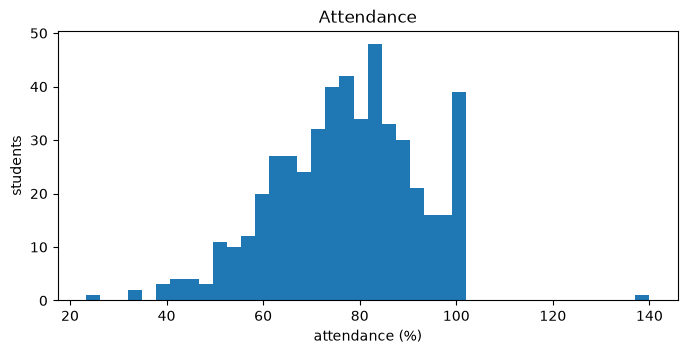

Students at exactly 100% attendance: 33


,student_id,study_hours,attendance,previous_grade,department,scholarship,passed
10,S0010,9.638194,140.0,50.94743,CS,No,0


In [7]:
print(df[["study_hours", "attendance", "previous_grade"]].describe().round(1))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df["attendance"], bins=40)
ax.set(xlabel="attendance (%)", ylabel="students", title="Attendance")
plt.show()
print("Students at exactly 100% attendance:", (df["attendance"] == 100).sum())
df[~df["attendance"].between(0, 100)]

## 3. Impossible values

An unusual value is rare but could be real. An impossible value breaks the meaning of the column. Attendance is a percentage, so it runs from 0 to 100.

`describe()` shows the maximum attendance is 140.0, and the histogram shows a single bar far to the right of everyone else. That is student S0010. No one attends 140% of classes, so this is an entry error or a different unit.

The histogram also shows a tall bar at exactly 100: 33 students have 100% attendance. That is possible, so we keep them, but a ceiling like this means the values at the top end are squashed together.

In [8]:
df.loc[~df["attendance"].between(0, 100), "attendance"] = np.nan
print("Missing attendance values:", df["attendance"].isna().sum())

Missing attendance values: 1


We can't recover the true attendance for S0010, so we mark it as missing. Session 2 will fill it in along with the other gaps. Deleting the whole row would throw away that student's other five good values for one bad one.

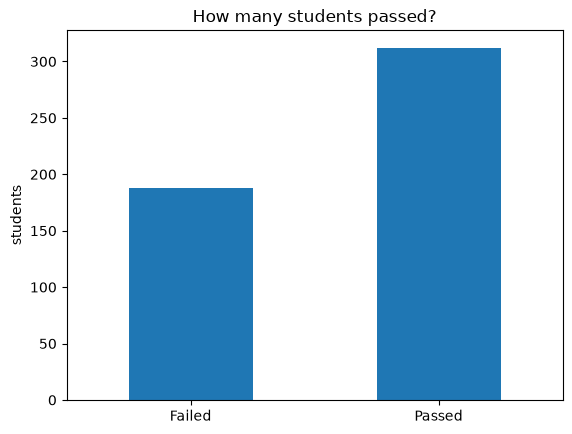

        students  share
Failed       188  0.376
Passed       312  0.624


In [9]:
counts = df["passed"].value_counts().sort_index()
counts.index = ["Failed", "Passed"]
counts.plot(kind="bar", title="How many students passed?", ylabel="students")
plt.xticks(rotation=0)
plt.show()
print(pd.DataFrame({"students": counts, "share": (counts / counts.sum()).round(3)}).to_string())

## 4. The target column

Before looking at features, check how common each outcome is: 312 students passed (62.4%) and 188 failed (37.6%).

This is a reasonable balance. A model that always answered "passed" would be right 62.4% of the time, which is the **baseline** from Session 0 and the number any real model must beat. If the split were 99% to 1%, accuracy would tell us almost nothing; Session 4 shows exactly that.

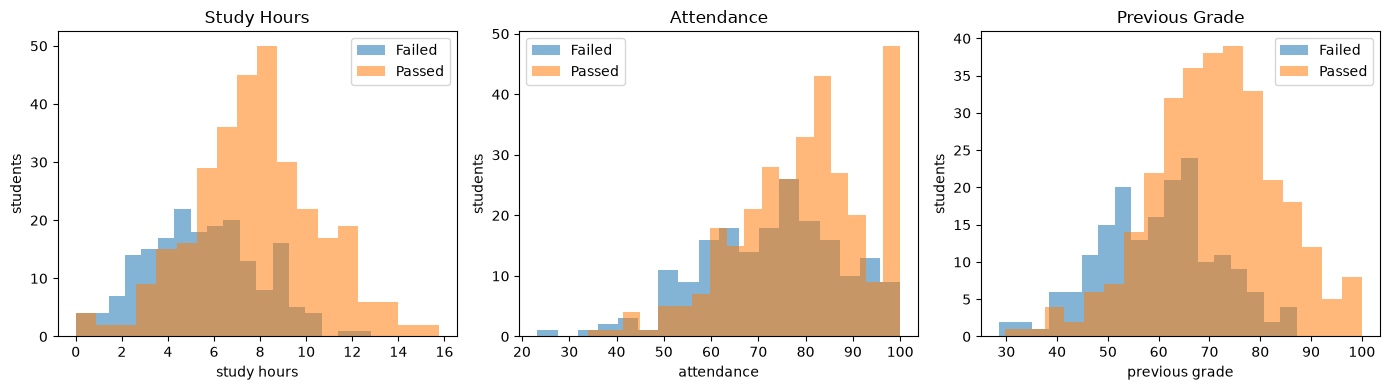

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column in zip(axes, ["study_hours", "attendance", "previous_grade"]):
    for outcome, label in [(0, "Failed"), (1, "Passed")]:
        ax.hist(df.loc[df["passed"] == outcome, column].dropna(), bins=18, alpha=0.55, label=label)
    ax.set(title=column.replace("_", " ").title(), xlabel=column.replace("_", " "), ylabel="students")
    ax.legend()
plt.tight_layout()
plt.show()

In [11]:
print(df.groupby("passed")[["study_hours", "attendance", "previous_grade"]].median().round(1).rename(index={0: "failed", 1: "passed"}))
for column, high, low in [("study_hours", 10, 4), ("previous_grade", 80, 50), ("attendance", 90, 60)]:
    above, below = df[df[column] > high], df[df[column] < low]
    print(f"{column}: above {high} -> {len(above)} students, {above['passed'].mean():.0%} passed;  below {low} -> {len(below)} students, {below['passed'].mean():.0%} passed")

        study_hours  attendance  previous_grade
passed                                         
failed          5.5        74.2            60.5
passed          7.8        81.1            71.7
study_hours: above 10 -> 69 students, 93% passed;  below 4 -> 79 students, 32% passed
previous_grade: above 80 -> 73 students, 92% passed;  below 50 -> 53 students, 28% passed
attendance: above 90 -> 96 students, 74% passed;  below 60 -> 60 students, 40% passed


## 5. Which features separate the outcomes?

Each plot compares the students who passed (orange) with those who failed (blue). The orange bars are taller because more students passed.

- **Study hours:** the median for students who failed is 5.5 hours, against 7.8 for those who passed. Of the 69 students who studied more than 10 hours, 93% passed; of the 79 who studied under 4 hours, 32% did.
- **Previous grade:** the same pattern, slightly stronger. The median is 60.5 for failed students and 71.7 for passed. Of the 73 students above 80, 92% passed; of the 53 below 50, 28% did.
- **Attendance:** the weakest separation. The medians are 74.2 and 81.1, and even among the 96 students above 90% attendance, 74% passed.

In every plot the colours overlap heavily. Knowing one feature of a student shifts the odds but doesn't settle the outcome, so a model will have to combine several features, and some mistakes will remain.

> **Pause:** the next table gives the pass rate per department. Which department do you expect to pass most often, and if it does, would the table tell you why?

In [12]:
by_department = df.groupby("department")["passed"].agg(["mean", "count"]).round(3)
by_department.columns = ["pass rate", "students"]
by_department

,pass rate,students
department,,
Business,0.525,101
CS,0.687,217
Engineering,0.593,167


Categories are easier to compare as rates. The pass rate is 68.7% in CS, 59.3% in Engineering and 52.5% in Business (the department counts are in the table). The sample of 101 Business students is small, so that 52.5% could easily move by a few points with a different sample.

A gap like this has many possible causes: course difficulty, prior preparation, grading, or something not in the table. The table shows that the rates differ. It can't say why.

In [13]:
df[["study_hours", "attendance", "previous_grade", "passed"]].corr()["passed"].drop("passed").round(3)

study_hours       0.400
attendance        0.220
previous_grade    0.413
Name: passed, dtype: float64

**Correlation** summarises how strongly a number goes up and down together with another, on a scale from −1 to 1. Here it is computed between each numeric feature and `passed`:

- `previous_grade` 0.413
- `study_hours` 0.400
- `attendance` 0.220

The ranking matches the histograms: previous grade and study hours matter most, attendance least. All three are positive and well below 1, which fits the heavy overlap we saw. A correlation near zero would not prove there is no relationship, since it only detects straight-line patterns (see Going deeper).

In [14]:
pd.DataFrame({"unique values": df.nunique(), "of rows": len(df)})

,unique values,of rows
student_id,500,500
study_hours,499,500
attendance,467,500
previous_grade,477,500
department,3,500
scholarship,2,500
passed,2,500


## 6. A column that should not be a feature

`student_id` has 500 different values in 500 rows: every student has their own. A flexible model could memorise which IDs passed, which would be no use for a new student. We keep it to identify rows and leave it out of the features.

A related danger is a column recorded *after* the outcome, such as a certificate issued to students who passed. It would predict the target almost perfectly and be useless in practice, because you only have it once the answer is known. This is **data leakage**, and Session 2 demonstrates it.

## 7. From findings to decisions

A finding is only useful when it leads to an action. This is the list from today:

| Finding | Decision |
|---|---|
| One student appears twice | Dropped the copy (done above) |
| One attendance value is 140 | Marked as missing (done above); will be filled in Session 2 |
| 22 previous grades and 15 departments are missing | Fill in using training data only (Session 2) |
| 33 students sit at 100% attendance | Keep; note the ceiling |
| Pass rate is 62.4% | Baseline accuracy to beat is 0.624 |
| `student_id` is unique per row | Leave out of the features |
| Features overlap heavily between outcomes | Expect an imperfect model |

Exploring doesn't stop here. When a model later makes a strange mistake, come back to the data and look again.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## A summary table can hide the shape

The mean and standard deviation summarise a column in two numbers. Different shapes can give the same two numbers. Below, one sample has a single hump and the other has two, and both have mean −0.05 and standard deviation 0.98. Only the histogram shows the difference, which is why we plot a column as well as describing it.

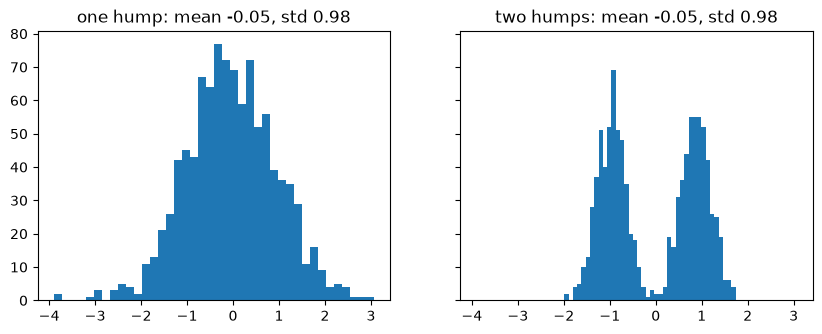

In [15]:
rng = np.random.default_rng(0)
single = rng.normal(0, 1, 1000)
double = np.concatenate([rng.normal(-1.5, 0.5, 500), rng.normal(1.5, 0.5, 500)])
double = (double - double.mean()) / double.std() * single.std() + single.mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True, sharey=True)
for ax, values, name in zip(axes, [single, double], ["one hump", "two humps"]):
    ax.hist(values, bins=40)
    ax.set_title(f"{name}: mean {values.mean():.2f}, std {values.std():.2f}")
plt.show()

## Correlation and its limits

The Pearson correlation between two columns $X$ and $Y$ is their covariance divided by the product of their standard deviations:

$$
r_{XY}=\frac{\operatorname{cov}(X,Y)}{s_X\,s_Y}.
$$

It runs from −1 (one goes up as the other goes down) to 1 (they rise together). It measures straight-line association only. If $Y=X^2$ and $X$ is spread evenly around zero, $Y$ is completely determined by $X$ and the correlation is still about zero. Correlation also says nothing about cause: students who study more may pass more because of the studying, or because motivated students do both.

## Missing values come in kinds

Statisticians separate three cases. **Missing completely at random** means the gap has nothing to do with any value, as with our planted gaps. **Missing at random** means it depends on other columns you can see (new students have no previous grade, and you know who is new). **Missing not at random** means it depends on the missing value itself, such as weak students leaving a field blank. Each case calls for a different treatment, and the third can't be detected from the table alone.